
# Lab 8: Monte Carlo Markov Chain (MCMC)

**Exercise 1**:

* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


In [1]:

print("Integrales Monte Carlo")

# 1.1 Integral simple: int_0^4 x^(1/2) dx
N_puntos = 1000000
a, b = 0, 4

# Generamos puntos aleatorios en el intervalo [a, b]
x_rand = np.random.uniform(a, b, N_puntos)
# Evaluamos la función
f_x = np.sqrt(x_rand)
# Calculamos el promedio multiplicado por el ancho del intervalo
integral_1 = (b - a) * np.mean(f_x)
analitico_1 = 16 / 3

print(f"Integral 1 (MC)       : {integral_1:.6f}")
print(f"Integral 1 (Analítico): {analitico_1:.6f}")
print(f"Error relativo        : {abs(integral_1 - analitico_1)/analitico_1 * 100:.4f}%\n")

# 1.2 Integral doble: int_{x=0}^{2} int_{y=0}^{1} x y^2 dy dx
x_min, x_max = 0, 2
y_min, y_max = 0, 1

x_rand2 = np.random.uniform(x_min, x_max, N_puntos)
y_rand2 = np.random.uniform(y_min, y_max, N_puntos)

f_xy = x_rand2 * (y_rand2 ** 2)
# El "volumen" de nuestra base de integración
area_base = (x_max - x_min) * (y_max - y_min)
integral_2 = area_base * np.mean(f_xy)
analitico_2 = 2 / 3

print(f"Integral 2 (MC)       : {integral_2:.6f}")
print(f"Integral 2 (Analítico): {analitico_2:.6f}")
print(f"Error relativo        : {abs(integral_2 - analitico_2)/analitico_2 * 100:.4f}%\n")




--- EJERCICIO 1: Integrales Monte Carlo ---
Integral 1 (MC)       : 5.334657
Integral 1 (Analítico): 5.333333
Error relativo        : 0.0248%

Integral 2 (MC)       : 0.666485
Integral 2 (Analítico): 0.666667
Error relativo        : 0.0273%



**Exercise 2**:

Read about the Ising's model 1D, 2D and 3D.

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  

--- EJERCICIO 2: Modelo de Ising 2D ---
Calculando simulación (esto puede tomar unos segundos)...


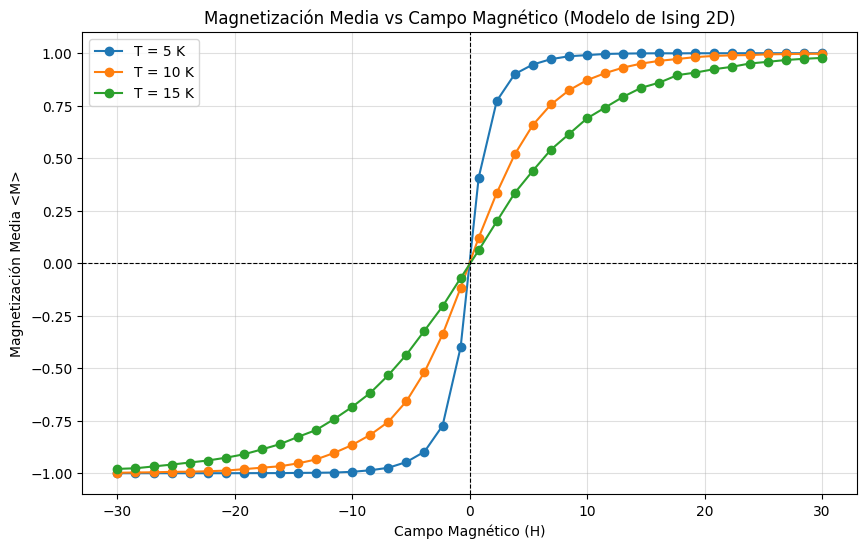

In [3]:
print("--- EJERCICIO 2: Modelo de Ising 2D ---")
print("Calculando simulación (esto puede tomar unos segundos)...")

def metropolis_step(lattice, T, H, J=1.0):
    """Realiza un barrido completo de la red usando el algoritmo de Metrópolis"""
    L = lattice.shape[0]
    for _ in range(L * L):
        # Elegir un átomo al azar
        i = np.random.randint(L)
        j = np.random.randint(L)
        S = lattice[i, j]

        # Suma de los spines de los primeros vecinos (con condiciones de frontera periódicas)
        vecinos = lattice[(i+1)%L, j] + lattice[(i-1)%L, j] + \
                  lattice[i, (j+1)%L] + lattice[i, (j-1)%L]

        # Variación de energía al invertir el spin. E = -J*sum(S_i*S_j) - H*sum(S_i)
        # dE = E_nueva - E_vieja = 2 * J * S * vecinos + 2 * H * S
        dE = 2 * S * (J * vecinos + H)

        # Criterio de aceptación
        if dE < 0 or np.random.rand() < np.exp(-dE / T):
            lattice[i, j] = -S

    return lattice

def simular_magnetizacion(L, T, H, eq_steps=100, mc_steps=300):
    """Simula la red para un T y H dados, y retorna la magnetización media"""
    # Inicializar red aleatoria con spines +1 y -1
    lattice = np.random.choice([-1, 1], size=(L, L))

    # Termalización (alcanzar el equilibrio estadístico)
    for _ in range(eq_steps):
        metropolis_step(lattice, T, H)

    # Medición de la magnetización
    mag_total = 0
    for _ in range(mc_steps):
        metropolis_step(lattice, T, H)
        mag_total += np.sum(lattice)

    # Promedio por espín y por paso
    return mag_total / (mc_steps * L * L)

# Parámetros solicitados
T_valores = [5, 10, 15]
H_valores = np.linspace(-30, 30, 40)
L = 15 # Tamaño de la red 15x15 (ajustar a 30 si deseas más precisión a costa de tiempo de cómputo)

plt.figure(figsize=(10, 6))

for T in T_valores:
    M_T = []
    for H in H_valores:
        mag = simular_magnetizacion(L, T, H)
        M_T.append(mag)

    plt.plot(H_valores, M_T, marker='o', label=f'T = {T} K')

plt.title('Magnetización Media vs Campo Magnético (Modelo de Ising 2D)')
plt.xlabel('Campo Magnético (H)')
plt.ylabel('Magnetización Media <M>')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()